# Aerodynamics Assignment on Vortex Panel Method 
### BY: Naman Jain, SC26M013

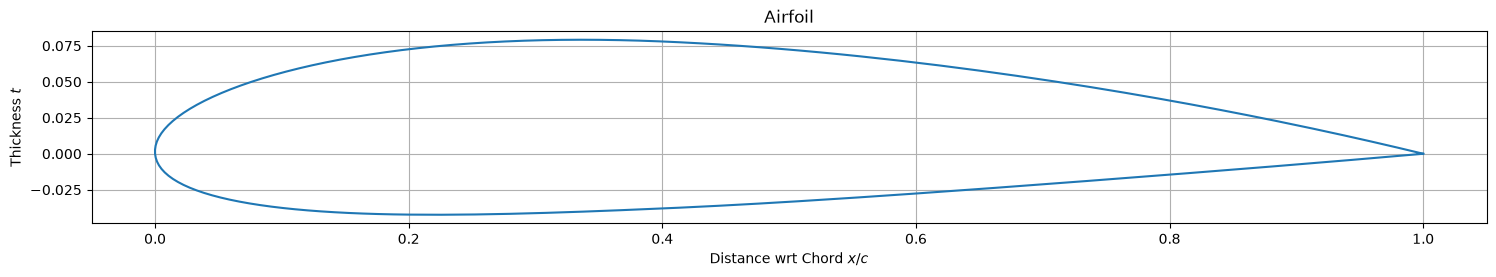

In [136]:
import numpy as np
import matplotlib.pyplot as plt

# Airfoil Plotting
a = 100 ## Number of points for plotting 
beta = np.linspace(0, np.pi, a)
x = 0.5 * (1 - np.cos(beta))

m = 2 / 100       # Maximum Camber
p = 4 / 10        # Location of Maximum Camber
t = 12 / 100     # Maximum Thickness

def airfoil_generation(x, m, p, t):
    x_u = np.zeros(len(x))
    x_l = np.zeros(len(x))
    y_u = np.zeros(len(x))
    y_l = np.zeros(len(x))
    y_t = np.zeros(len(x))
    y_c = np.zeros(len(x))
    dyc_dx = np.zeros(len(x))
    theta = np.zeros(len(x))

    
    #Original Airfoil Generation 
    if p == 0:
        for i in range(len(x)):
            y_t[i] = 5*t*(0.2969*(x[i]**0.5)        # Thickness distribution
                       - 0.1260*x[i]
                       - 0.3516*(x[i]**2)
                       + 0.2843*(x[i]**3)
                       - 0.1036*(x[i]**4))
            x_u[i] = x[i]  # Upper and lower surfaces
            x_l[i] = x[i] 
            y_u[i] = y_t[i]
            y_l[i] = - y_t[i]
    else:
        for i in range(len(x)):
            y_t[i] = 5*t*(0.2969*(x[i]**0.5)        # Thickness distribution
                       - 0.1260*x[i]
                       - 0.3516*(x[i]**2)
                       + 0.2843*(x[i]**3)
                       - 0.1036*(x[i]**4))
        
            if 0 <= x[i] <= p:                      # Camber line and slope
                y_c[i] = (m / p**2) * (2*p*x[i] - x[i]**2)
                dyc_dx[i] = (2*m / p**2) * (p - x[i])
        
            elif p < x[i] <= 1:
                y_c[i] = (m / (1-p)**2) * ((1 - 2*p) + 2*p*x[i] - x[i]**2)
                dyc_dx[i] = (2*m / (1-p)**2) * (p - x[i])
                
            theta[i] = np.arctan(dyc_dx[i])         # Angle of camber line
            
            x_u[i] = x[i] - y_t[i]*np.sin(theta[i]) # Upper and lower surfaces
            x_l[i] = x[i] + y_t[i]*np.sin(theta[i])
            y_u[i] = y_c[i] + y_t[i]*np.cos(theta[i])
            y_l[i] = y_c[i] - y_t[i]*np.cos(theta[i])
              
    x_u[0], y_u[0] = 0.0, 0.0
    x_l[0], y_l[0] = 0.0, 0.0

    x_u[-1], y_u[-1] = 1.0, 0.0
    x_l[-1], y_l[-1] = 1.0, 0.0
    
    # Combine upper and lower surfaces
    x_full = np.concatenate((x_u[::-1], x_l[1:]))
    y_full = np.concatenate((y_u[::-1], y_l[1:]))
    
    return x_full, y_full

a = airfoil_generation(x, m, p, t)

plt.figure(figsize=(18, 2.5))
plt.plot(a[0], a[1])
plt.xlabel("Distance wrt Chord $x/c$")
plt.ylabel("Thickness $t$")
plt.title("Airfoil")
plt.grid(True)
plt.show()


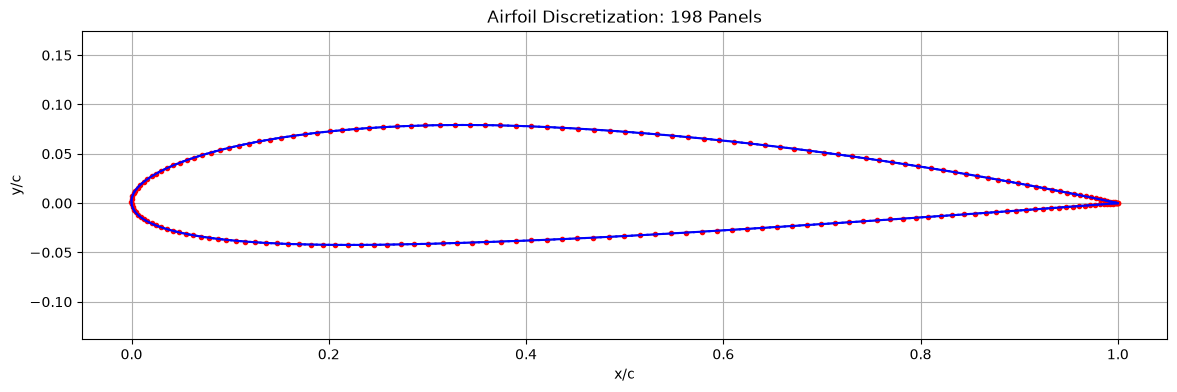

In [137]:
def panel_gen(x, y):
    x1 = x[:-1]
    y1 = y[:-1]
    x2 = x[1:]
    y2 = y[1:]

    N = len(x) - 1
    l = np.sqrt((x2 - x1)**2 + (y2 - y1)**2)
    
    x_c = (x1 + x2)/2
    y_c1 = (y1 + y2)/2

    theta_p = np.arctan2((y2 - y1),(x2 - x1))
    normal_vector = np.array([np.sin(theta_p), -np.cos(theta_p)])
    
    return N, l, x_c, y_c1, theta_p, normal_vector, x1, x2, y1, y2

x_airfoil, y_airfoil = airfoil_generation(x, m, p, t)
N, l, x_c, y_c1, theta_p, normal_vector, x1, x2, y1, y2 = panel_gen(x_airfoil, y_airfoil)

# Plot panels and collocation points
plt.figure(figsize=(14, 4))
plt.plot(x_airfoil, y_airfoil, 'k-', linewidth=1)
plt.plot(x_c, y_c1, 'ro', markersize=3)

for i in range(N):
    plt.plot([x1[i], x2[i]], [y1[i], y2[i]], 'b-')
plt.axis('equal')
plt.xlabel('x/c')
plt.ylabel('y/c')
plt.title(f'Airfoil Discretization: {N} Panels')
plt.grid(True)
plt.show()

In [138]:
def J_matrix(N, l, x_c, y_c1, theta_p, x1, x2, y1, y2):
    J = np.zeros((N, N))
    K = np.zeros((N,N))
    
    for i in range(N):
        normal_vector0 = np.array([np.sin(theta_p[i]), - np.cos(theta_p[i])])
        tangent_vector0 = np.array([np.cos(theta_p[i]), np.sin(theta_p[i])])
        
        for j in range(N):
            A_j = np.array([x1[j], y1[j]])
            P_i = np.array([x_c[i], y_c1[i]])

            tangent_vector1 = np.array([np.cos(theta_p[j]), np.sin(theta_p[j])])
            normal_vector1 = np.array([np.sin(theta_p[j]), - np.cos(theta_p[j])])

            x_ij = np.dot(P_i - A_j, tangent_vector1)
            y_ij = np.dot(P_i - A_j, normal_vector1)

            if i == j:
                I1 = np.pi
                I2 = 0
                
            else:
                r1 = x_ij**2 + y_ij**2
                r2 = (x_ij - l[j])**2 + y_ij**2
    
                I1 = np.arctan2((l[j]*y_ij),(x_ij*(x_ij - l[j]) + y_ij**2))
                I2 = 0.5*np.log(r1/r2)

            J[i, j] = (np.dot(normal_vector0, tangent_vector1))*I1 - (np.dot(normal_vector0, normal_vector1))*I2
            K[i,j] = (np.dot(tangent_vector0, tangent_vector1)*I1 - np.dot(tangent_vector0, normal_vector1)*I2)

    return J, K

J = J_matrix(N, l, x_c, y_c1, theta_p, x1, x2, y1, y2)[0]
K  = J_matrix(N, l, x_c, y_c1, theta_p, x1, x2, y1, y2)[1]
print(J,  K)

[[ 0.          1.94561454  0.88686848 ...  0.83966981  1.73459293
  -0.66177491]
 [-0.51096359  0.          1.46580647 ...  1.18868203 -0.53248762
  -0.49969951]
 [-0.1671554  -0.78883369  0.         ... -0.39564139 -0.72338701
  -0.16640912]
 ...
 [ 0.16641486  0.72342168  0.3956153  ...  0.          0.78885091
   0.16716004]
 [ 0.49970732  0.53245897 -1.18878807 ... -1.46578219  0.
   0.51096991]
 [ 0.66176245 -1.73465569 -0.83974076 ... -0.8868486  -1.945601
   0.        ]] [[3.14159265e+00 1.62328278e-04 2.08716350e-04 ... 2.73357759e-01
  7.49514240e-01 2.50236391e+00]
 [1.65354724e-05 3.14159265e+00 2.07487260e-04 ... 6.74924681e-01
  2.19358425e+00 4.21320797e-02]
 [3.09234125e-05 7.24310566e-05 3.14159265e+00 ... 1.82550774e+00
  1.52925095e-01 4.18340093e-03]
 ...
 [4.16004245e-03 1.52876841e-01 1.82556912e+00 ... 3.14159265e+00
  1.71821719e-05 7.33711501e-06]
 [4.21201016e-02 2.19361231e+00 6.74806237e-01 ... 4.92171257e-05
  3.14159265e+00 3.93425284e-06]
 [2.50237162e+00 7

In [139]:
def vortex_panel_method_0(N, V_inf, alpha, J, theta_p):
    normal_vector = np.array([np.sin(theta_p), -np.cos(theta_p)])

    alpha1 = np.deg2rad(alpha)
    u_inf = V_inf*np.cos(alpha1)
    v_inf = V_inf*np.sin(alpha1)
    V_total = np.array([u_inf, v_inf])
    V_normal = np.dot(V_total, normal_vector)

    A = np.zeros((N,N))
    b = np.zeros(N)

    A[:N-1, :] = J[:N-1, :]
    b[:N-1] = -2 * np.pi * V_normal[:N-1]

    #Kutta Condition
    A[N-1, 0] = 1.0
    A[N-1, N-1] = 1.0

    b[N-1] = 0.0

    # Solve for vortex strengths
    gamma = np.linalg.solve(A, b)

    return gamma, A, b

Vortex Strengths:
[   1.46717922  -41.2246253    69.91418582 -103.725129     81.04887557
  -90.520604     64.50191667  -75.91781197   51.90384425  -65.94890002
   43.27405672  -59.15577318   37.15540532  -54.31899809   32.60513385
  -50.72127503   29.07777125  -47.94896642   26.25314345  -45.75551391
   23.93531837  -43.98703476   21.99851163  -42.54286913   20.35815177
  -41.35430766   18.95500532  -40.37274071   17.74614434  -39.56278534
   16.69959175  -38.89812417   15.79101277  -38.35887863   15.00159025
  -37.92988684   14.31661333  -37.59953843   13.72451233  -37.35896721
   13.21618228  -37.2014845    12.78449732  -37.12218333   12.42395147
  -37.1176739    12.13037775  -37.1859355    11.90069752  -37.3263032
   11.73262009  -37.53969356   11.62405613  -37.82954585   11.5712377
  -38.1921228    11.40099077  -38.53452454   11.48675685  -39.03928633
   11.65670137  -39.61606166   11.91641169  -40.27403134   12.2715524
  -41.02368286   12.73039355  -41.87764091   13.30388288  -42.

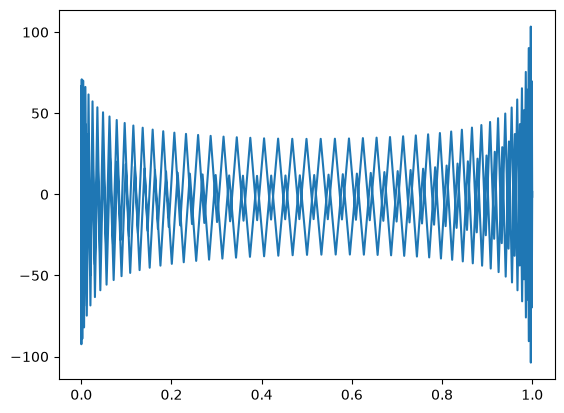

In [144]:
gamma = vortex_panel_method_0(N, 10, 5, J, theta_p)

print("Vortex Strengths:")
print(gamma[0])

plt.plot(x_c, gamma[0])
plt.show()

Pressure coefficients:
[   0.97847385  -15.99469731  -47.87993379 -106.58902387  -64.68920231
  -80.93979748  -40.60497255  -56.63514174  -25.94009048  -42.49257414
  -17.72643985  -33.99405501  -12.80524145  -28.50553554   -9.63094754
  -24.72647741   -7.45516781  -21.99103381   -5.89227541  -19.93567053
   -4.72899465  -18.34859227   -3.83934514  -17.09895714   -3.14454344
  -16.10178762   -2.59292227  -15.29958193   -2.14925639  -14.65213984
   -1.78876365  -14.13064064   -1.49356084  -13.7140357    -1.2504771
  -13.38676316   -1.04965417  -13.1372529    -0.88362239  -12.95692431
   -0.74667474  -12.83950449   -0.63443372  -12.78056495   -0.5435457
  -12.77721716   -0.47146064  -12.82793799   -0.41626601  -12.9325291
   -0.37654374  -13.09228593   -0.35118681  -13.31074539   -0.33893542
  -13.58638244   -0.29982591  -13.84909582   -0.31945583  -14.24065877
   -0.35878687  -14.69432342   -0.42000867  -15.219976     -0.50590998
  -15.82942555   -0.6206292   -16.53736808   -0.769933   

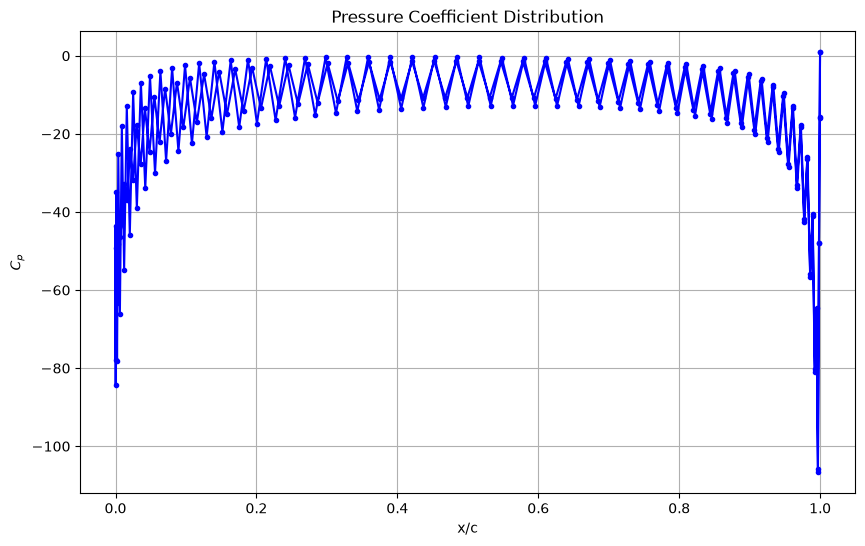

In [145]:
alpha1 = np.deg2rad(5)
Cp = 1 - (gamma[0]/10)**2

print("Pressure coefficients:")
print(Cp)

plt.figure(figsize=(10,6))

plt.plot(x_c, Cp, 'bo-', markersize=3)
plt.xlabel("x/c")
plt.ylabel("$C_p$")
plt.title("Pressure Coefficient Distribution")

plt.grid(True)
plt.show()